# 수수컴정 중간발표 결과 확인

최소 기준선 macro-F1은 **0.427**, 댓글만 쓴 TF-IDF + Logistic Regression은 **0.647**이다. 맥락을 추가한 PLM fine-tuning은 **0.809 / 0.778**을 기록했다. TF-IDF의 맥락 조건은 임계값 조정 후 혐오 Recall이 **0.303 → 0.535**로 회복됐다.

원실험·PLM: 소지연 / 확장·임계값 비교: 안지수 / 통합·CPU 재현·이 노트북: 진군학.
팀 제공 두 ZIP의 CSV를 읽는다. CPU 베이스라인은 WSL에서 재현했고, PLM은 제공 결과이다. 이 노트북은 추가 모델 학습이나 Notion 업로드를 하지 않는다.

## 조건과 데이터

KOCOH v2 3,000행, 혐오 764 / 비혐오 2,236. 같은 Context를 공유하는 Set을 합친 77개 post_group으로 바깥 5-fold를 만들었다(seed 42). TF-IDF 임계값은 바깥 train의 내부 묶음 4-fold OOF에서 고른 뒤 train 전체로 재학습한다. OOF는 각 행을 학습에 사용하지 않은 모델이 만든 예측을 뜻한다.

표의 SD는 **5개 test fold 사이의 표본 표준편차(ddof=1)**이다. seed 5회 반복이나 신뢰구간이 아니다. PLM은 epoch 3, max_length 128, 단일 seed 결과이다.

저장소 루트 또는 `notebooks/`에서 실행한다. 결과 읽기에는 데이터·가중치가 필요 없으며, CPU 학습 재현 명령은 README에 있다.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / 'results/midterm').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'results/midterm/provided').is_dir(), '저장소 루트 또는 notebooks에서 실행하세요.'
sys.path.insert(0, str(ROOT))
from src.midterm.summarize import main, tables
main()
base, tuned, plm, summary, thresholds = tables()
print('제공 결과:', len(base), 'baseline rows +', len(tuned), 'threshold rows +', len(plm), 'PLM rows = 170 rows')
print('고정 임계값 결과가 일부 중복되므로 학습 170회를 뜻하지 않습니다.')

표 2개 및 PNG/PDF 그림 2쌍 저장 완료
제공 결과: 50 baseline rows + 60 threshold rows + 60 PLM rows = 170 rows
고정 임계값 결과가 일부 중복되므로 학습 170회를 뜻하지 않습니다.


## 입력 조건별 비교

,model,method,condition,macro_f1_mean,macro_f1_std,recall_hate_mean,recall_hate_std
0,Dummy most_frequent,default threshold,-,0.427,0.005,0.000,0.000
3,TF-IDF LogReg,default threshold,Comment-only,0.647,0.014,0.528,0.045
6,TF-IDF LogReg,default threshold,Context+Comment,0.633,0.033,0.303,0.031
8,TF-IDF LogReg,default threshold,Context-only,0.465,0.077,0.162,0.091
12,KcELECTRA-base-v2022,finetune,Comment-only,0.672,0.021,0.842,0.036
13,KcELECTRA-base-v2022,finetune,Context+Comment,0.809,0.049,0.679,0.106
18,klue-roberta-base,finetune,Comment-only,0.637,0.028,0.810,0.065
19,klue-roberta-base,finetune,Context+Comment,0.778,0.012,0.690,0.125


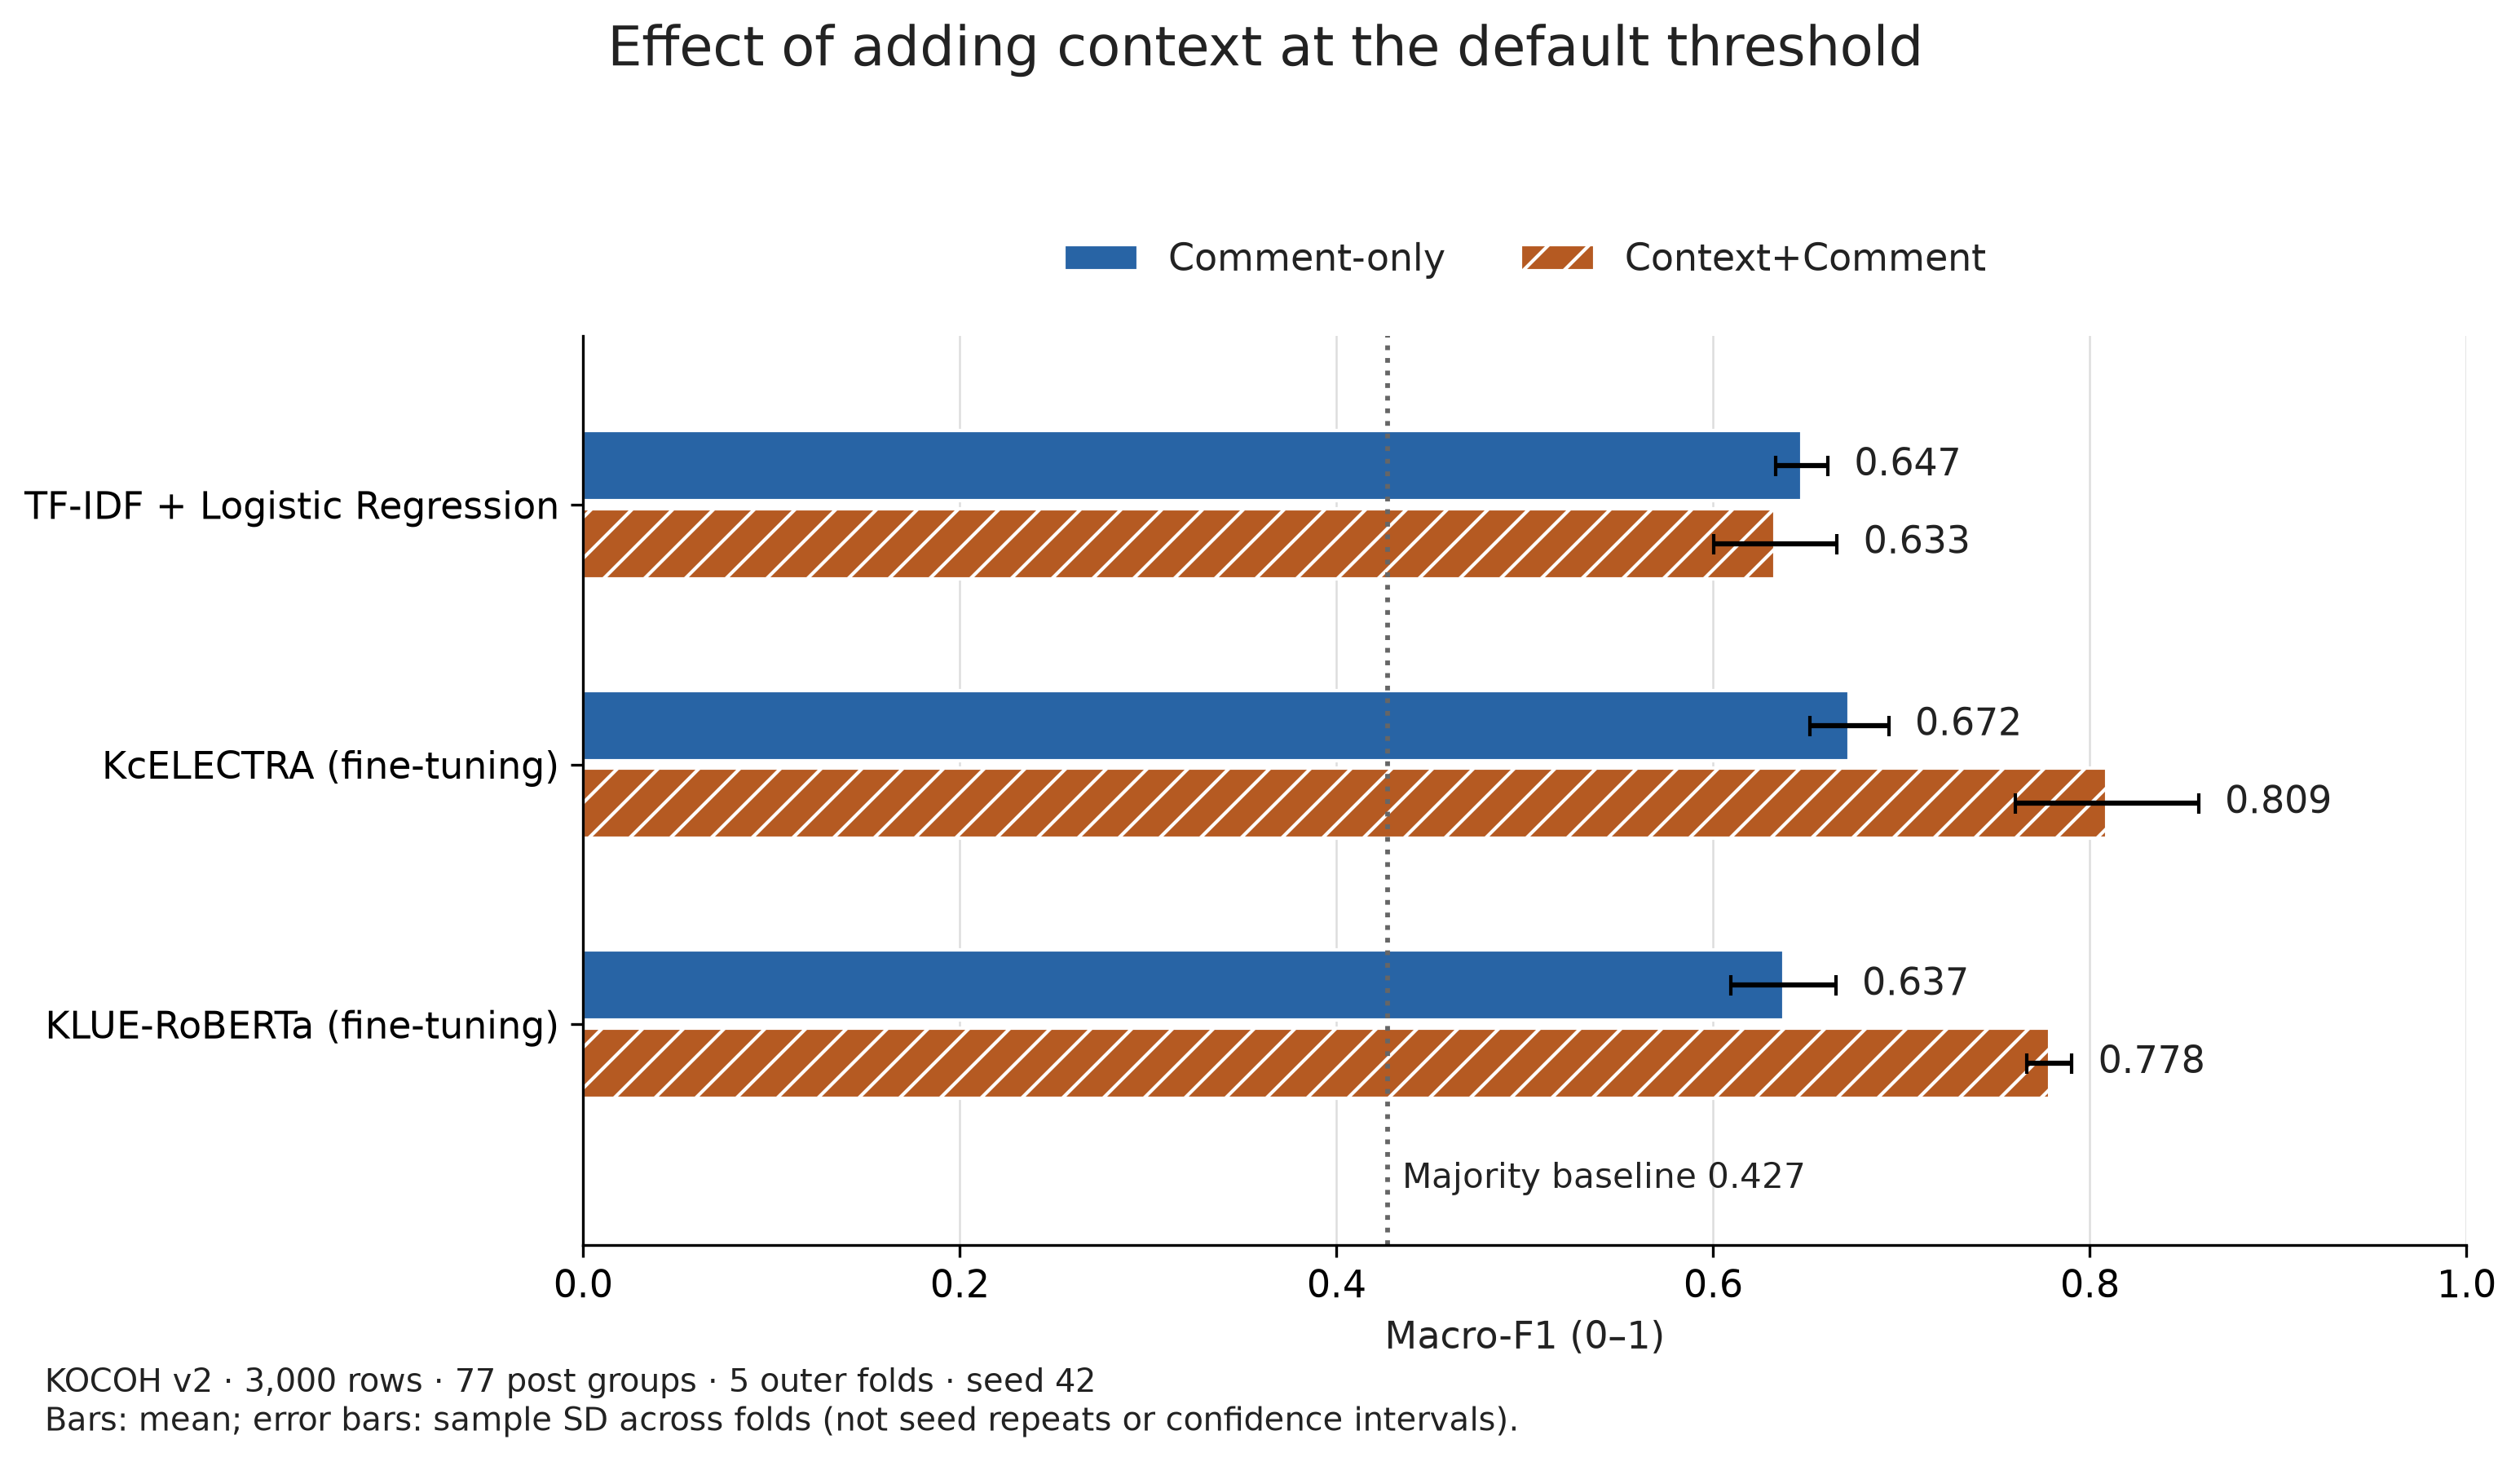

In [2]:
selection = summary[(summary['model'].isin(['Dummy most_frequent','TF-IDF LogReg'])) | (summary['method']=='finetune')]
display(selection.round(3))
display(Image(filename=str(ROOT/'figures/midterm/01_context_comparison.png'), width=950))

PLM fine-tuning은 같은 fold에서 맥락 추가 시 macro-F1이 높았다. TF-IDF의 기본 임계값에서는 0.647 → 0.633이었다. 모델 간 비교는 모두 기본 판정 규칙으로 맞췄다. 이 결과만으로 맥락과 댓글의 관계를 이해했다고 결론내리지 않는다.

## TF-IDF 임계값 조정

,model,condition,rule,macro_f1_mean,macro_f1_std,recall_hate_mean,recall_hate_std,pr_auc_mean,pr_auc_std
0,TF-IDF LogReg,Comment-only,0.5 고정,0.647,0.014,0.528,0.045,0.437,0.021
1,TF-IDF LogReg,Comment-only,OOF 조정,0.644,0.013,0.588,0.064,0.437,0.021
4,TF-IDF LogReg,Context+Comment,0.5 고정,0.633,0.033,0.303,0.031,0.524,0.058
5,TF-IDF LogReg,Context+Comment,OOF 조정,0.662,0.027,0.535,0.038,0.524,0.058


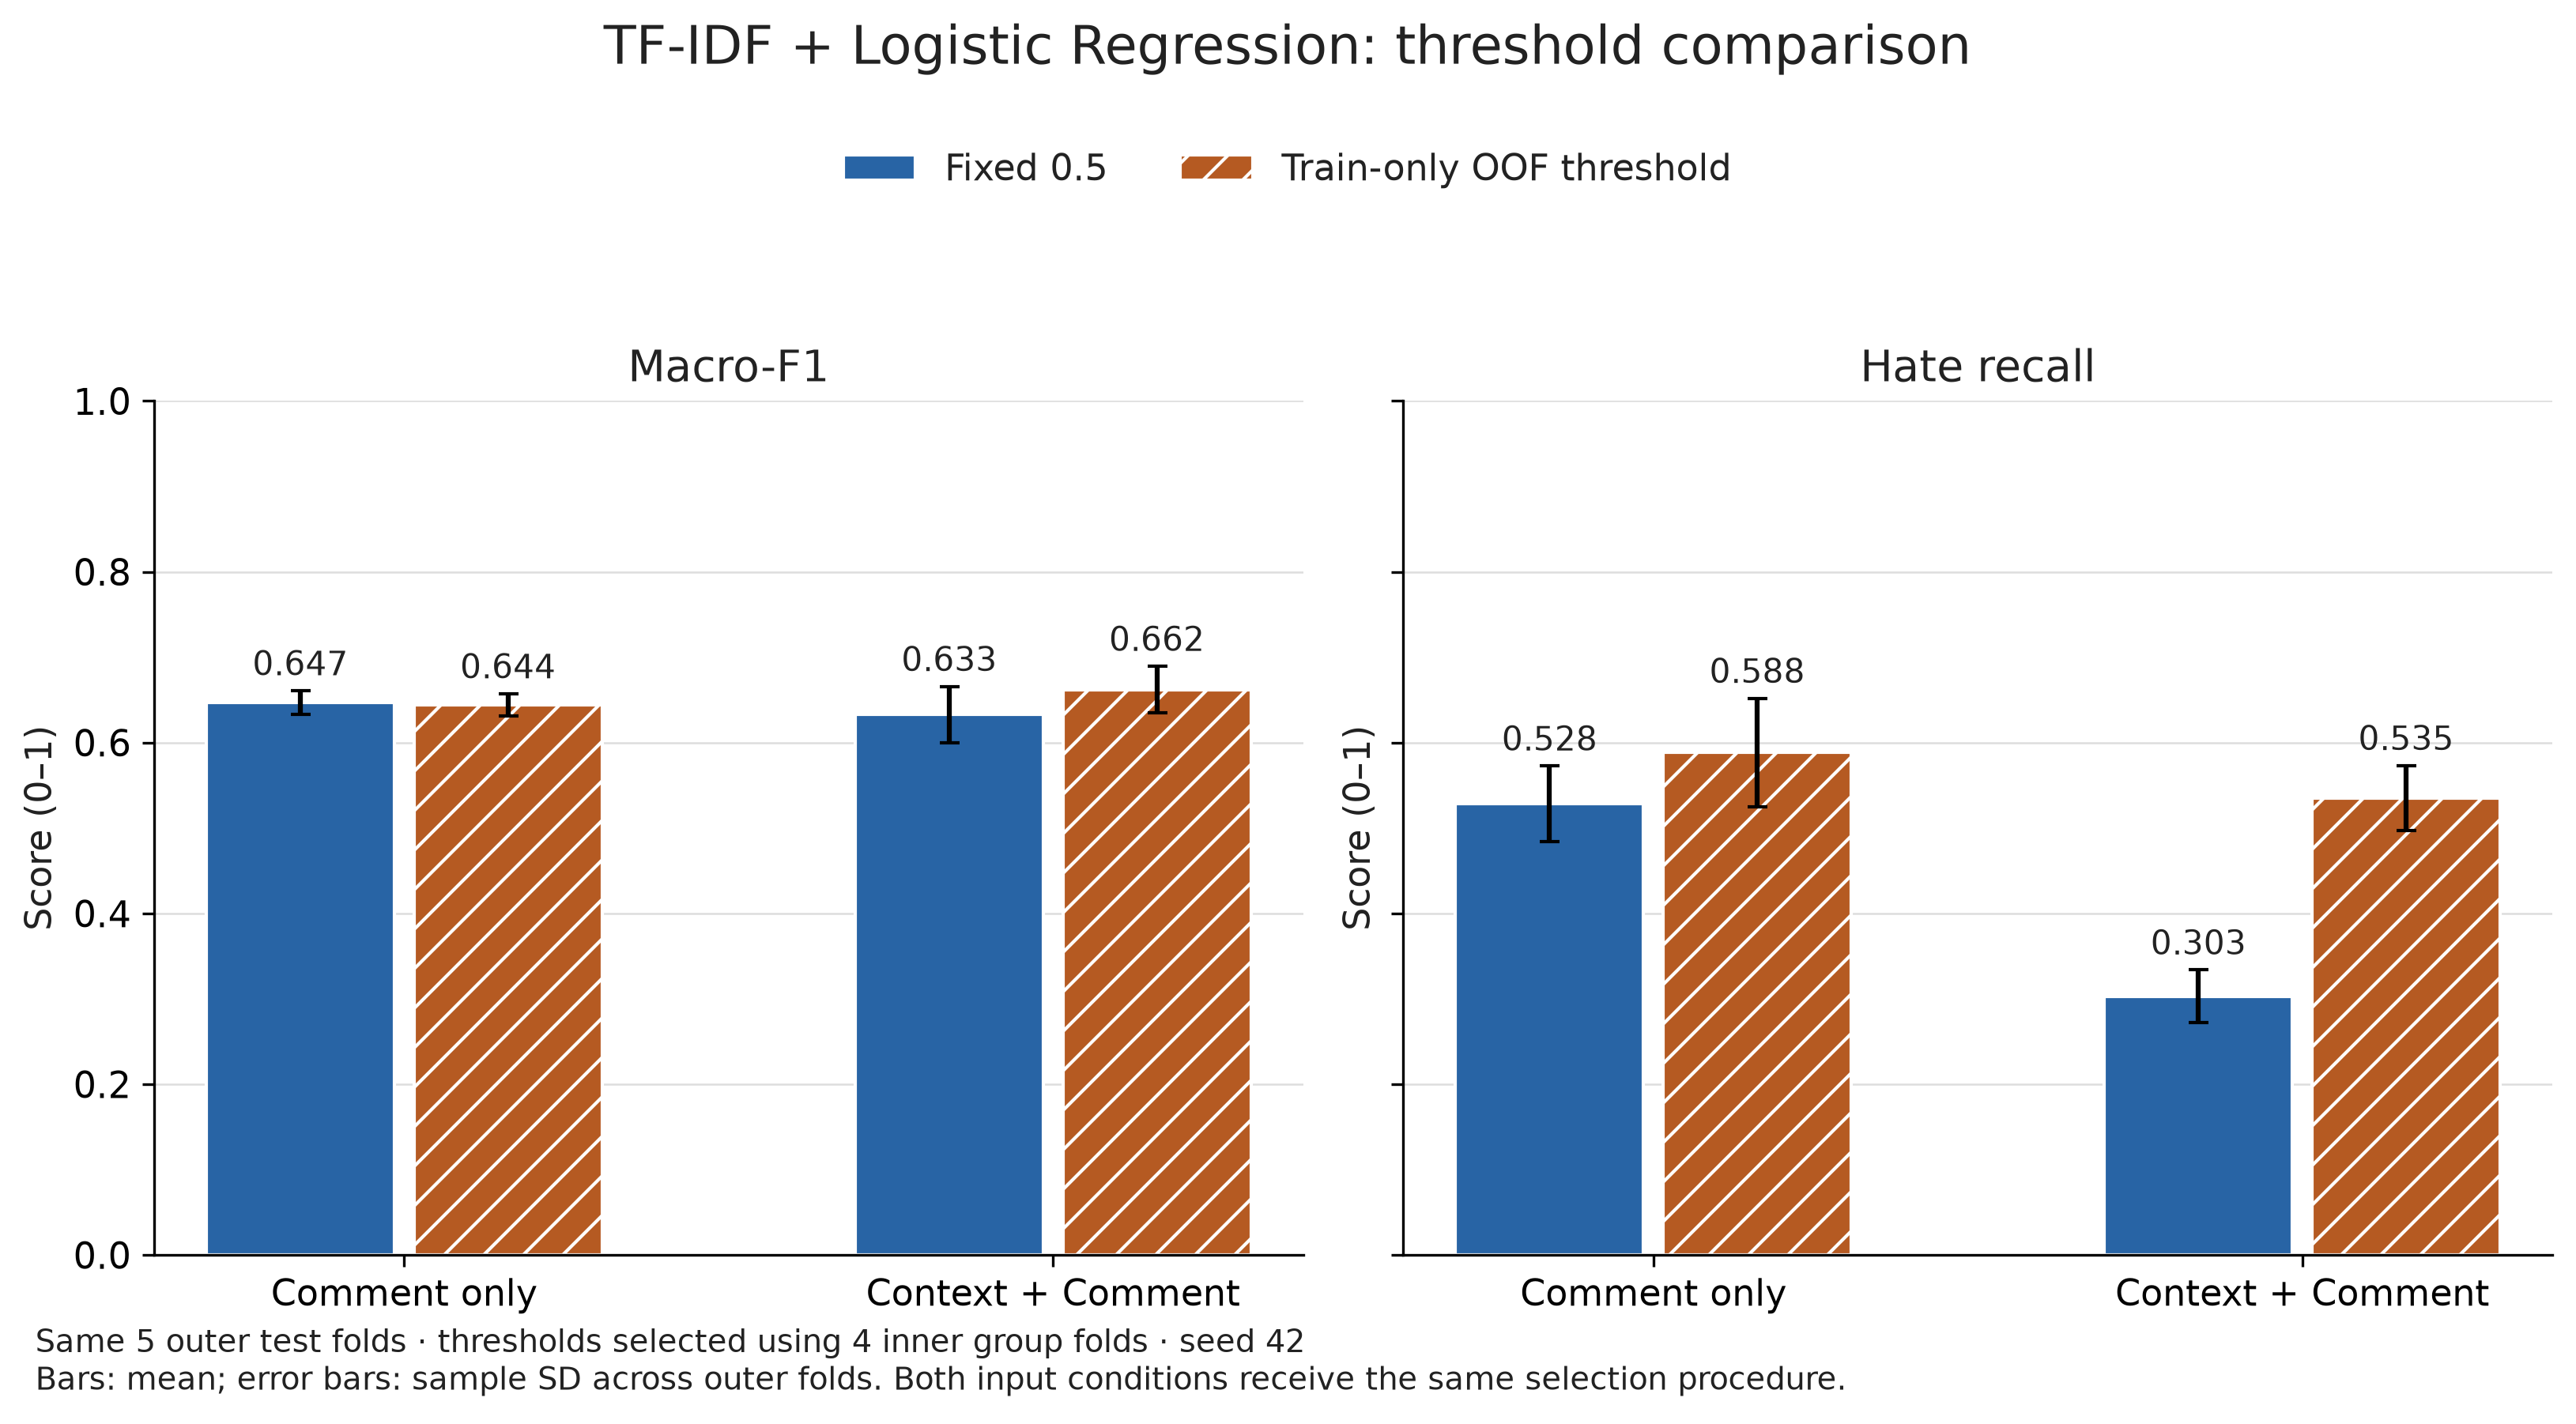

In [3]:
display(thresholds[(thresholds.model=='TF-IDF LogReg') & (thresholds.condition!='Context-only')].round(3))
display(Image(filename=str(ROOT/'figures/midterm/02_threshold_comparison.png'), width=950))

두 입력 조건 모두 같은 내부 검증 절차를 적용했다. 맥락 조건의 Recall은 0.303 → 0.535, 댓글만 조건은 0.528 → 0.588이다. 따라서 조정 후 맥락 추가에 따른 Recall 차이는 −0.053이다. `pr_auc` 열은 sklearn의 **average precision(AP)** 계산값이며 사다리꼴 적분 PR-AUC와 구별한다.

## 재현 확인과 해석의 한계

In [4]:
check = json.loads((ROOT/'results/midterm/validation.json').read_text())
display(pd.DataFrame(check['csv_comparisons']))
display(pd.read_csv(ROOT/'results/midterm/comment_oracle_check.csv').round(6))
print('댓글별 고정 라벨의 사후 최댓값, fold 평균:', round(check['comment_oracle_mean'], 6))

,file,status,rows
0,plm_folds.csv,provided_only,60
1,baseline_folds.csv,match_atol_1e-6,40
2,baseline_v2_folds.csv,match_atol_1e-6,50
3,baseline_v2_by_type.csv,match_atol_1e-6,120
4,comment_only_ceiling.csv,match_atol_1e-6,5
5,baseline_v3_folds.csv,match_atol_1e-6,60
6,baseline_v3_by_type.csv,match_atol_1e-6,240
7,split_assignment_v2.csv,match_atol_1e-6,15000
8,inner_val_composition.csv,match_atol_1e-6,20


,fold,macro_f1,tp,fp
0,0,0.709737,165,165
1,1,0.739097,152,151
2,2,0.735897,152,152
3,3,0.734685,146,146
4,4,0.730536,147,147


댓글별 고정 라벨의 사후 최댓값, fold 평균: 0.729991


- 약 0.730은 이 데이터와 5개 fold에서 같은 댓글에 같은 답을 내는 결정론적 규칙의 사후 최댓값이다. test 정답을 사용한 계산이므로 학습 모델의 성능이나 일반적인 혐오탐지 상한이 아니다.
- 이 값을 넘는 것만으로 맥락 이해가 입증되지는 않는다. PLM Context-only와 유형별 오류 분석이 필요하다.
- fold들은 학습 데이터를 공유한다. 기존 대응표본 t-검정 p값은 탐색적 근거로 보며 5개의 독립 실험으로 해석하지 않는다. [Bengio & Grandvalet (2004)](https://www.jmlr.org/papers/v5/grandvalet04a.html).
- PLM 시간은 원자료의 Apple MPS 측정값이다. Colab T4의 30분 상한 확인은 10주차 계획이다.
- 10주차: 확률 저장, Context-only, seed 3회, T4 시간 확인. 11주차: PLM 임계값 조정·오류 분석·LoRA 검증과 최종 정리.